In [62]:
# Distributional makeup of behavior characteristics

(4, 4)


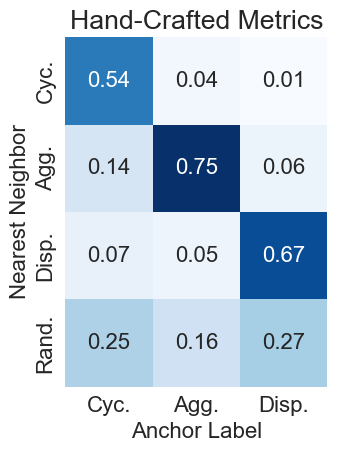

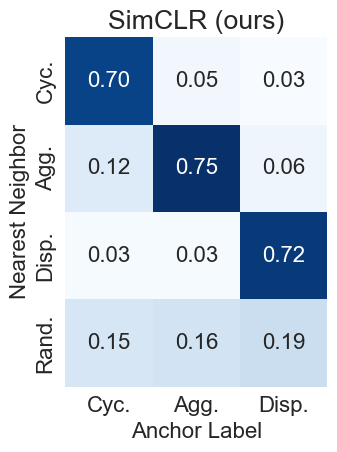

In [68]:
# Class confusion matrix for labeled data
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# BASELINE METRICS
confusion_matrix = np.array([
 [0.025, 0.539, 0.035, 0.012],
 [0.103, 0.141, 0.748, 0.055],
 [0.144, 0.067, 0.052, 0.665],
 [0.728, 0.253, 0.164, 0.268],
])

# SIMCLR METRICS
# SEED 1
simCLR_matrix_A = np.array([

 [0.081, 0.751, 0.053, 0.019],
 [0.227, 0.133, 0.842, 0.044],
 [0.102, 0.013, 0.012, 0.77],
[0.591, 0.103, 0.093, 0.166],
])

# SEED 2
simCLR_matrix_B = np.array([
     [0.063, 0.649, 0.047, 0.027],
     [0.184, 0.126, 0.737, 0.064],
     [0.122, 0.045, 0.036, 0.699],
    [0.631, 0.18, 0.181, 0.21],
]
)

# SEED 3
simCLR_matrix_C = np.array([
 [0.067, 0.698, 0.054, 0.032],
 [0.173, 0.105, 0.678, 0.067],
 [0.12, 0.043, 0.048, 0.703],
 [0.64, 0.155, 0.22, 0.198],
])

simCLR_matrix = ((simCLR_matrix_A + simCLR_matrix_B + simCLR_matrix_C) / 3)
print(simCLR_matrix.shape)

simCLR_matrix = simCLR_matrix[:, 1:]
confusion_matrix = confusion_matrix[:, 1:]

plt.rcParams.update({'font.size': 16})

sns.heatmap(
    confusion_matrix,
    annot=True,
    fmt='.2f',
    cbar=False,
    cmap='Blues',
    xticklabels=["Cyc.", "Agg.", "Disp."],
    yticklabels=["Cyc.", "Agg.", "Disp.", "Rand.",],
    square=True,
)
plt.title("Hand-Crafted Metrics")
plt.xlabel("Anchor Label")
plt.ylabel("Nearest Neighbor")
plt.tight_layout()
plt.savefig("brown_confusion_matrix.pdf", bbox_inches='tight')

plt.figure()
sns.heatmap(
    simCLR_matrix,
    annot=True,
    fmt='.2f',
    cbar=False,
    cmap='Blues',
    xticklabels=["Cyc.", "Agg.", "Disp."],
    yticklabels=["Cyc.", "Agg.", "Disp.", "Rand.",],
    square=True,
)
plt.title("SimCLR (ours)")
plt.xlabel("Anchor Label")
plt.ylabel("Nearest Neighbor")
plt.tight_layout()
plt.savefig("simclr_confusion_matrix.pdf", bbox_inches='tight')

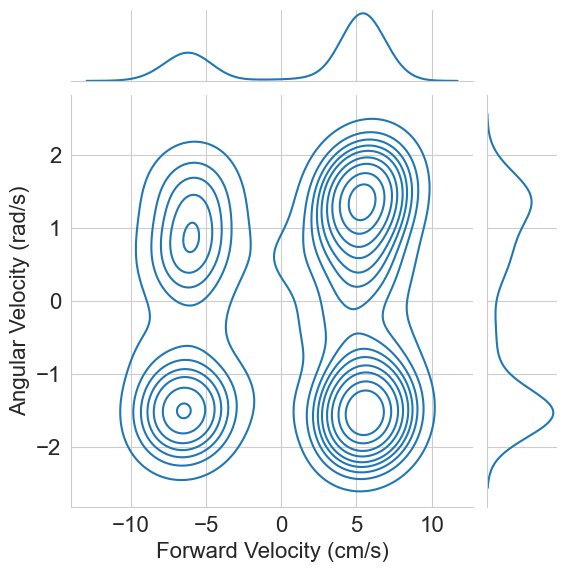

In [64]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Analyze the distribution of the controller data

df = pd.read_csv("~/Desktop/DevProjects/RobotSwarmSimulator/demo/evolution/out/g_1728583862_final_1728584235.csv")
df.columns = ["v0", "w0", "v1", "w1"]

df["v0"] /= 3
df["v1"] /= 3

sns.jointplot(
    data=df,
    x="v1", y="w1",
    kind="kde"
)
# plt.title("Controller Distribution for Novelty Search (sensor=0)")
plt.xlabel("Forward Velocity (cm/s)")
plt.ylabel("Angular Velocity (rad/s)")
plt.show()


KeyboardInterrupt: 

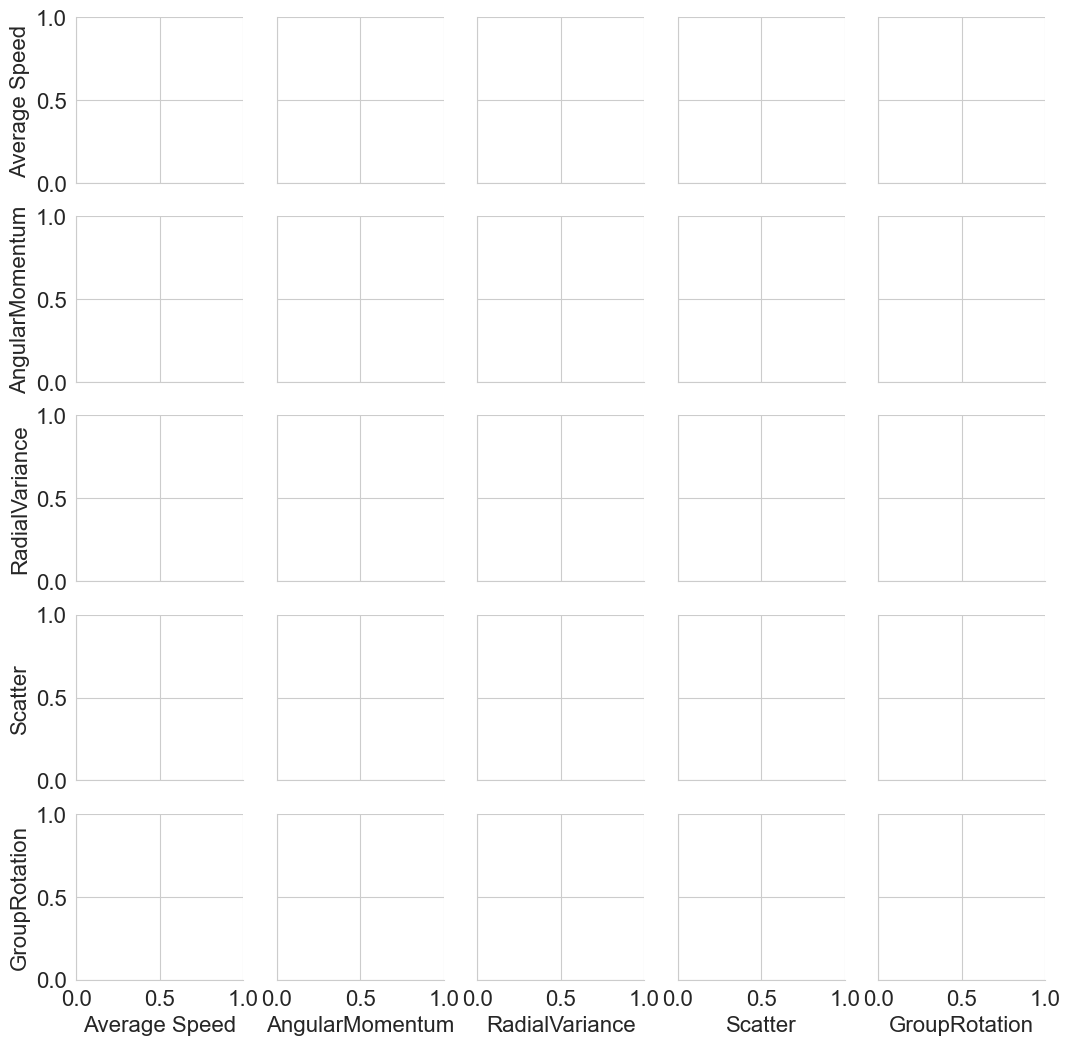

In [65]:
# Analyze the distribution of the behavior data

df = pd.read_csv("~/Desktop/DevProjects/RobotSwarmSimulator/demo/evolution/out/b_1728583862_final_1728584235.csv")
df.columns = ["Average Speed", "AngularMomentum", "RadialVariance", "Scatter", "GroupRotation"]

# sns.displot(df, x="Average Speed", kind="kde")
# plt.show()
g = sns.PairGrid(df)
g.map_lower(sns.kdeplot, fill=True)
g.map_upper(sns.kdeplot, fill=True)
g.map_diag(sns.histplot, kde=True)
plt.show()